# 01 – Verkenning: wanneer en waarom zijn treinen te laat?

Dit notebook beantwoordt zes vragen over een jaar treinverkeer in Nederland (november 2025 t/m oktober 2026), elk met **één grafiek en één zin conclusie**. Alles leest uit de dbt-marts in `data/ov.duckdb` (maak die eerst met `python -m ov_vertraging.load` en `dbt build`, of via Dagster).

**Definities**
- *Vertraagd* = vertrokken met ≥ 5 minuten vertraging (`is_delayed_5min`). Geannuleerde vertrekken tellen niet mee (apart cijfer).
- *Binnenlandse treinen* = Intercity, Intercity direct, Sprinter, Stoptrein en Sneltrein, vertrekkend vanaf een Nederlands station. Internationale treinen (ICE, Eurostar, …) bekijken we apart, omdat hun vertraging vaak al van over de grens komt.
- Dit zijn **verbanden, geen oorzaken**: vorst valt bv. vooral in de winter, wanneer het ook om andere redenen drukker en donkerder is.

*Bron treindata: [Rijden de Treinen](https://www.rijdendetreinen.nl/open-data) (CC BY 4.0). Weer: KNMI.*

In [1]:
import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import requests

from ov_vertraging.config import DB_PATH, RAW_DIR

con = duckdb.connect(str(DB_PATH), read_only=True)


def q(sql: str) -> pd.DataFrame:
    """Zware aggregaties in DuckDB, alleen het (kleine) resultaat naar pandas."""
    return con.sql(sql).df()


DOMESTIC = "('Intercity', 'Intercity direct', 'Sprinter', 'Stoptrein', 'Sneltrein')"
con.execute(f"""
    CREATE OR REPLACE TEMP VIEW binnenland AS
    SELECT f.*
    FROM marts.fct_departures AS f
    JOIN marts.dim_station AS s ON s.station_code = f.station_code AND s.is_dutch
    WHERE f.is_delayed_5min IS NOT NULL AND f.service_type IN {DOMESTIC}
""")

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
WEEKDAGEN = ["ma", "di", "wo", "do", "vr", "za", "zo"]

q("""
    SELECT count(*) AS vertrekken,
           round(100 * avg(is_delayed_5min::int), 2) AS pct_vertraagd,
           min(departure_date) AS van, max(departure_date) AS tot
    FROM binnenland
""")

,vertrekken,pct_vertraagd,van,tot
0,17207857,4.06,2025-11-01,2026-11-01


## 1. Wat is het slechtste uur en de slechtste weekdag?

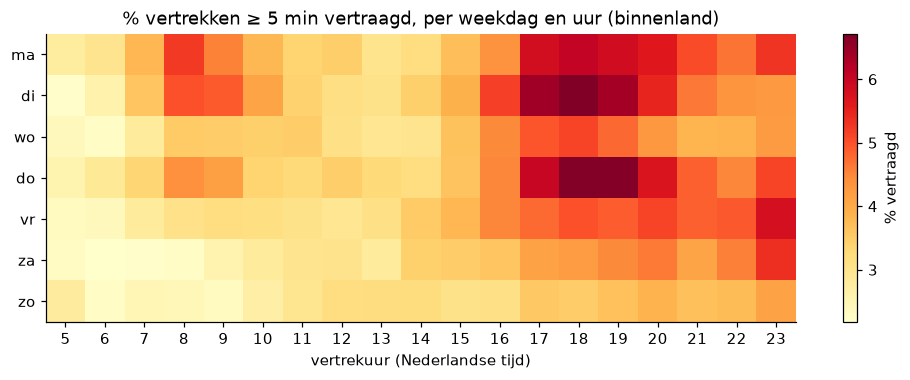

Slechtste uur: 18:00 (5.4%), beste uur: 5:00 (2.5%)
Slechtste dag: di (4.4%), beste dag: zo (3.2%)


In [2]:
uur_dag = q("""
    SELECT departure_weekday AS dag, departure_hour AS uur,
           100 * avg(is_delayed_5min::int) AS pct, count(*) AS n
    FROM binnenland
    WHERE departure_hour BETWEEN 5 AND 23   -- nachturen: te weinig treinen
    GROUP BY ALL
""")
heat = uur_dag.pivot(index="dag", columns="uur", values="pct").sort_index()

fig, ax = plt.subplots(figsize=(11, 3.4))
im = ax.imshow(heat.values, aspect="auto", cmap="YlOrRd")
ax.set_yticks(range(7), WEEKDAGEN)
ax.set_xticks(range(len(heat.columns)), heat.columns)
ax.set_xlabel("vertrekuur (Nederlandse tijd)")
ax.set_title("% vertrekken ≥ 5 min vertraagd, per weekdag en uur (binnenland)")
fig.colorbar(im, ax=ax, label="% vertraagd")
plt.show()

per_uur = uur_dag.groupby("uur").apply(lambda d: (d.pct * d.n).sum() / d.n.sum())
per_dag = uur_dag.groupby("dag").apply(lambda d: (d.pct * d.n).sum() / d.n.sum())
print(
    f"Slechtste uur: {per_uur.idxmax()}:00 ({per_uur.max():.1f}%), "
    f"beste uur: {per_uur.idxmin()}:00 ({per_uur.min():.1f}%)"
)
print(
    f"Slechtste dag: {WEEKDAGEN[per_dag.idxmax() - 1]} ({per_dag.max():.1f}%), "
    f"beste dag: {WEEKDAGEN[per_dag.idxmin() - 1]} ({per_dag.min():.1f}%)"
)

**Conclusie:** de avondspits (rond 18 uur, ~5,4 %) is het slechtst en de vroege ochtend (5 uur, ~2,5 %) het best — vertraging stapelt zich over de dag op; doordeweeks is het slechter (dinsdag het slechtst) dan in het weekend (zondag het best).

### 1b. Is er een seizoenseffect (herfst)?

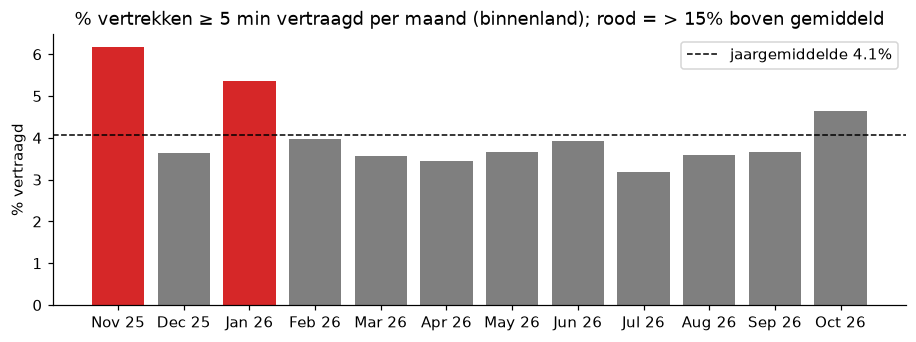

,maand,pct
0,2025-11-01,6.18
1,2025-12-01,3.65
2,2026-01-01,5.37
3,2026-02-01,3.98
4,2026-03-01,3.56
5,2026-04-01,3.45
6,2026-05-01,3.67
7,2026-06-01,3.93
8,2026-07-01,3.18
9,2026-08-01,3.60


In [3]:
maand = q("""
    SELECT date_trunc('month', departure_date) AS maand,
           100 * avg(is_delayed_5min::int) AS pct
    FROM binnenland GROUP BY 1
    HAVING count(*) >= 100000   -- geen losse nachtritten van na de laatste dag
    ORDER BY 1
""")
gemiddeld = q("SELECT 100 * avg(is_delayed_5min::int) AS p FROM binnenland").p[0]

fig, ax = plt.subplots(figsize=(10, 3.2))
kleuren = ["#d62728" if p > gemiddeld * 1.15 else "#7f7f7f" for p in maand.pct]
ax.bar(maand.maand.dt.strftime("%b %y"), maand.pct, color=kleuren)
ax.axhline(gemiddeld, ls="--", c="k", lw=1, label=f"jaargemiddelde {gemiddeld:.1f}%")
ax.set_ylabel("% vertraagd")
ax.set_title("% vertrekken ≥ 5 min vertraagd per maand (binnenland); rood = > 15% boven gemiddeld")
ax.legend()
plt.show()
maand.assign(pct=maand.pct.round(2))

**Conclusie:** ja — november (bladeren op het spoor, herfststormen) en januari (sneeuw en vorst) springen eruit, de zomer en het voorjaar zijn het rustigst.

## 2. Wat zijn de minst betrouwbare trajecten?

Een *traject* is een rit tussen twee opeenvolgende stops (bv. `WH-ZL` = Wijhe → Zwolle). We tellen alleen trajecten met minstens 3.000 vertrekken, zodat toevalstreffers niet bovenaan komen.

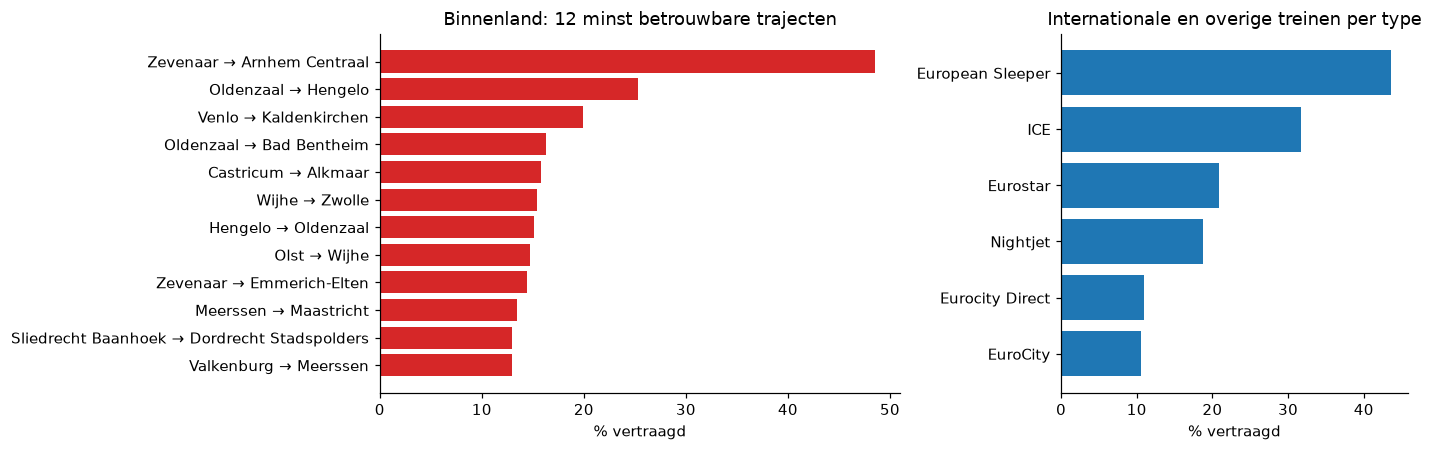

,traject,vertrekken,pct
0,Zevenaar → Arnhem Centraal,5124,48.6
1,Oldenzaal → Hengelo,5524,25.3
2,Venlo → Kaldenkirchen,4987,20.0
3,Oldenzaal → Bad Bentheim,5623,16.3
4,Castricum → Alkmaar,7498,15.8
5,Wijhe → Zwolle,12946,15.4
6,Hengelo → Oldenzaal,5524,15.2
7,Olst → Wijhe,12948,14.7
8,Zevenaar → Emmerich-Elten,5167,14.4
9,Meerssen → Maastricht,8594,13.4


In [4]:
trajecten = q("""
    SELECT a.station_name || ' → ' || b.station_name AS traject,
           count(*) AS vertrekken,
           100 * avg(is_delayed_5min::int) AS pct
    FROM binnenland AS f
    JOIN marts.dim_station AS a ON a.station_code = f.station_code
    JOIN marts.dim_station AS b ON b.station_code = f.next_station_code
    GROUP BY f.route_code, a.station_name, b.station_name
    HAVING count(*) >= 3000
    ORDER BY pct DESC LIMIT 12
""")
internationaal = q(f"""
    SELECT service_type AS treintype, count(*) AS vertrekken,
           100 * avg(is_delayed_5min::int) AS pct
    FROM marts.fct_departures
    WHERE is_delayed_5min IS NOT NULL AND service_type NOT IN {DOMESTIC}
    GROUP BY 1 HAVING count(*) >= 3000 ORDER BY pct DESC
""")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [3, 2]})
ax1.barh(trajecten.traject[::-1], trajecten.pct[::-1], color="#d62728")
ax1.set_xlabel("% vertraagd")
ax1.set_title("Binnenland: 12 minst betrouwbare trajecten")
ax2.barh(internationaal.treintype[::-1], internationaal.pct[::-1], color="#1f77b4")
ax2.set_xlabel("% vertraagd")
ax2.set_title("Internationale en overige treinen per type")
plt.tight_layout()
plt.show()
trajecten.assign(pct=trajecten.pct.round(1))

**Conclusie:** de minst betrouwbare trajecten liggen vooral bij de grens (Zevenaar, Oldenzaal, Venlo, Zuid-Limburg) en op de lijn Deventer–Zwolle, met 3 tot 12× zoveel vertraging als gemiddeld; internationale treinen zijn het onbetrouwbaarst omdat ze hun vertraging vaak al van over de grens meenemen (de ICE vertrekt in de meerderheid van de gevallen te laat).

## 3. Intercity of Sprinter?

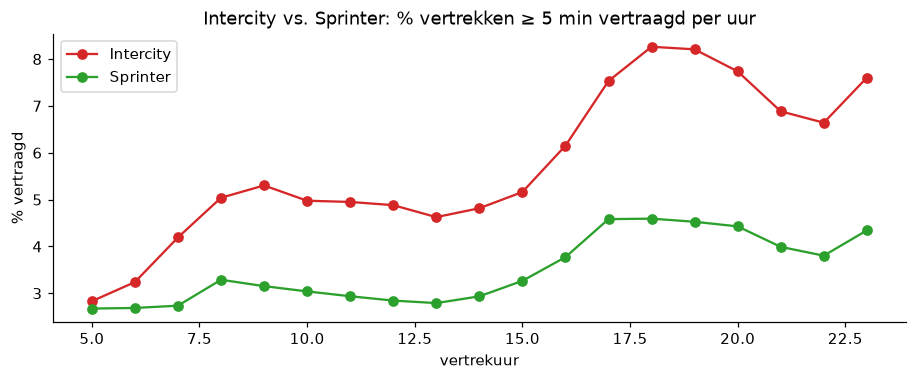

,service_type,vertrekken,pct_vertraagd,gem_vertraging_min
0,Intercity,3793680,6.07,1.05
1,Sprinter,8943823,3.59,0.71


In [5]:
type_uur = q("""
    SELECT service_type, departure_hour AS uur, 100 * avg(is_delayed_5min::int) AS pct
    FROM binnenland
    WHERE service_type IN ('Intercity', 'Sprinter') AND departure_hour BETWEEN 5 AND 23
    GROUP BY ALL ORDER BY uur
""")
totaal = q("""
    SELECT service_type, count(*) AS vertrekken,
           round(100 * avg(is_delayed_5min::int), 2) AS pct_vertraagd,
           round(avg(departure_delay_min), 2) AS gem_vertraging_min
    FROM binnenland WHERE service_type IN ('Intercity', 'Sprinter') GROUP BY 1
""")

fig, ax = plt.subplots(figsize=(10, 3.4))
for t, kleur in [("Intercity", "#d62728"), ("Sprinter", "#2ca02c")]:
    d = type_uur[type_uur.service_type == t]
    ax.plot(d.uur, d.pct, marker="o", label=t, color=kleur)
ax.set_xlabel("vertrekuur")
ax.set_ylabel("% vertraagd")
ax.set_title("Intercity vs. Sprinter: % vertrekken ≥ 5 min vertraagd per uur")
ax.legend()
plt.show()
totaal

**Conclusie:** een Intercity is op elk uur van de dag vaker vertraagd dan een Sprinter (ruwweg 6 % tegen 3,5 %) — langere ritten over drukke hoofdlijnen verzamelen meer vertraging dan korte stoptreinritten.

## 4. Wat doen wind, vorst en hevige neerslag?

Het weer komt van het dichtstbijzijnde KNMI-station dat de variabele meet, in het uur van vertrek. *Wind ≥ 7 Bft* is het uurgemiddelde; *windstoten* zijn de hoogste stoot in dat uur.

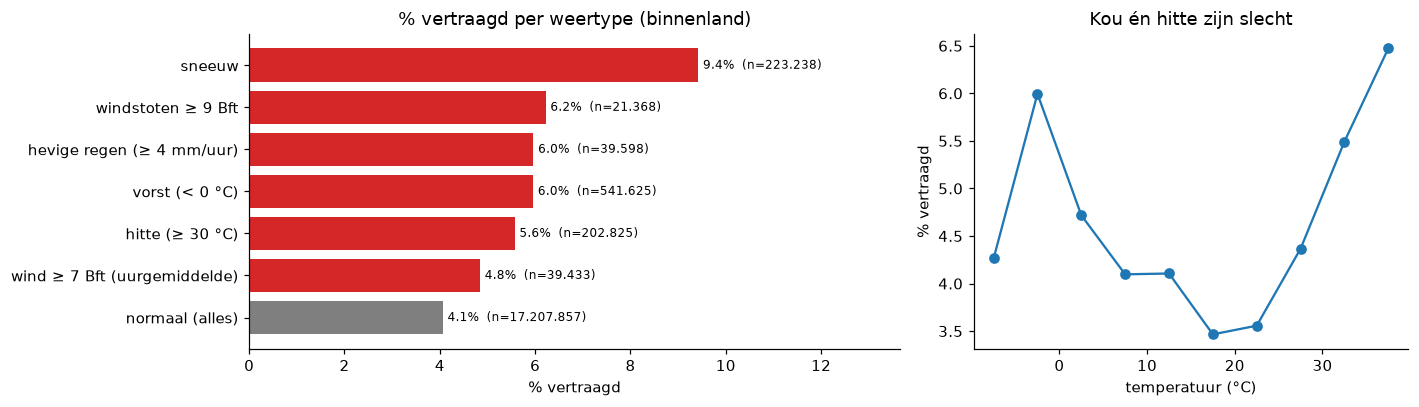

In [6]:
weer = q("""
    WITH c AS (
        SELECT 'normaal (alles)' AS weer, is_delayed_5min FROM binnenland
        UNION ALL SELECT 'wind ≥ 7 Bft (uurgemiddelde)', is_delayed_5min
            FROM binnenland WHERE wind_bft >= 7
        UNION ALL SELECT 'windstoten ≥ 9 Bft', is_delayed_5min
            FROM binnenland WHERE wind_gust_bft >= 9
        UNION ALL SELECT 'vorst (< 0 °C)', is_delayed_5min FROM binnenland WHERE is_frost
        UNION ALL SELECT 'hevige regen (≥ 4 mm/uur)', is_delayed_5min
            FROM binnenland WHERE is_heavy_rain
        UNION ALL SELECT 'sneeuw', is_delayed_5min FROM binnenland WHERE has_snow
        UNION ALL SELECT 'hitte (≥ 30 °C)', is_delayed_5min
            FROM binnenland WHERE temperature_c >= 30
    )
    SELECT weer, count(*) AS vertrekken, 100 * avg(is_delayed_5min::int) AS pct
    FROM c GROUP BY 1 ORDER BY pct
""")
temp = q("""
    SELECT floor(temperature_c / 5) * 5 AS t, count(*) AS n, 100 * avg(is_delayed_5min::int) AS pct
    FROM binnenland WHERE temperature_c IS NOT NULL GROUP BY 1 HAVING count(*) >= 5000 ORDER BY 1
""")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [3, 2]})
kleuren = ["#7f7f7f" if w.startswith("normaal") else "#d62728" for w in weer.weer]
ax1.barh(weer.weer, weer.pct, color=kleuren)
for i, (p, n) in enumerate(zip(weer.pct, weer.vertrekken, strict=True)):
    ax1.text(p + 0.1, i, f"{p:.1f}%  (n={n:,})".replace(",", "."), va="center", fontsize=8)
ax1.set_xlabel("% vertraagd")
ax1.set_xlim(0, weer.pct.max() * 1.45)
ax1.set_title("% vertraagd per weertype (binnenland)")
ax2.plot(temp.t + 2.5, temp.pct, marker="o", color="#1f77b4")
ax2.set_xlabel("temperatuur (°C)")
ax2.set_ylabel("% vertraagd")
ax2.set_title("Kou én hitte zijn slecht")
plt.tight_layout()
plt.show()

**Conclusie:** sneeuw verdubbelt de kans op vertraging ruwweg (≈ 9 % tegen 4 %), vorst, hevige regen, windstoten en hitte geven elk ~1,5–2 procentpunt extra, terwijl gemiddelde wind ≥ 7 Bft nauwelijks uitmaakt — windstoten zijn dus de betere maat voor het model.

## 5. Doorwerking: hoe vaak groeit 3 minuten vertraging uit tot ≥ 10 minuten?

Voor elk vertrek met precies *X* minuten vertraging kijken we of een latere stop van **dezelfde rit** ≥ 10 minuten vertraging haalt, en of de trein juist inloopt.

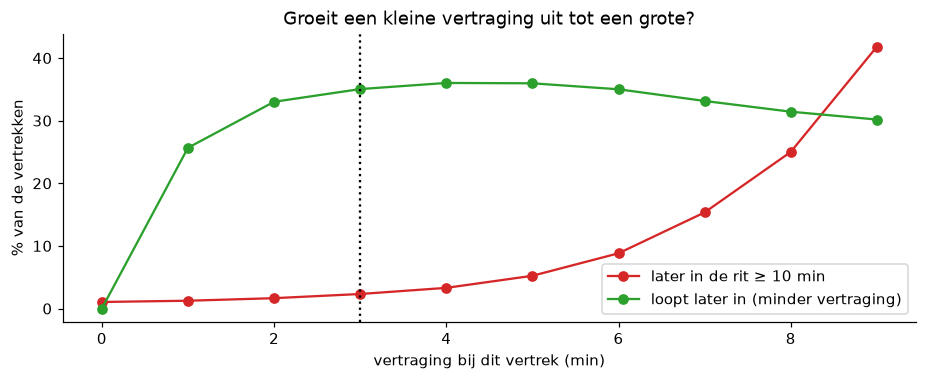

,vertraging_nu,vertrekken,pct_later_10_plus,pct_ingelopen
0,0,10593323,1.0,0.0
1,1,2452582,1.2,25.7
2,2,833186,1.7,33.0
3,3,420447,2.3,35.0
4,4,245279,3.3,36.0
5,5,153931,5.2,36.0
6,6,100407,8.8,35.0
7,7,70070,15.3,33.1
8,8,51189,25.0,31.4
9,9,39725,41.8,30.2


In [7]:
doorwerking = q("""
    WITH d AS (
        SELECT departure_delay_min AS nu,
               max(departure_delay_min) OVER (
                   PARTITION BY service_id ORDER BY stop_sequence
                   ROWS BETWEEN 1 FOLLOWING AND UNBOUNDED FOLLOWING
               ) AS later_max
        FROM binnenland
    )
    SELECT nu AS vertraging_nu, count(*) AS vertrekken,
           100 * avg((later_max >= 10)::int) AS pct_later_10_plus,
           100 * avg((later_max < nu)::int) AS pct_ingelopen
    FROM d WHERE nu BETWEEN 0 AND 9 AND later_max IS NOT NULL
    GROUP BY 1 ORDER BY 1
""")

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(
    doorwerking.vertraging_nu,
    doorwerking.pct_later_10_plus,
    marker="o",
    color="#d62728",
    label="later in de rit ≥ 10 min",
)
ax.plot(
    doorwerking.vertraging_nu,
    doorwerking.pct_ingelopen,
    marker="o",
    color="#2ca02c",
    label="loopt later in (minder vertraging)",
)
ax.axvline(3, ls=":", c="k")
ax.set_xlabel("vertraging bij dit vertrek (min)")
ax.set_ylabel("% van de vertrekken")
ax.set_title("Groeit een kleine vertraging uit tot een grote?")
ax.legend()
plt.show()
doorwerking.round(1)

**Conclusie:** zelden — van de treinen met 3 minuten vertraging haalt maar ~2,3 % later ≥ 10 minuten en loopt ruim een derde weer in; pas vanaf 6–7 minuten groeit vertraging duidelijk door (bij 9 minuten ruim 40 %).

## 6. De 5 slechtste dagen — en wat er gebeurde

Gerangschikt op % vertraagde vertrekken (binnenland), alleen volledige dagen.

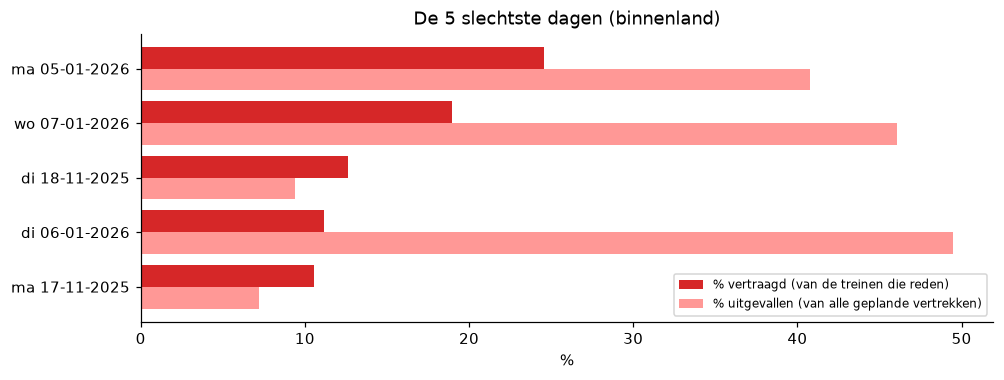

,datum,vertrekken,pct_vertraagd,pct_uitval,min_temp,max_windstoot_bft,sneeuw
0,2026-01-05,36843,24.6,40.8,-6.0,8,True
1,2026-01-07,32211,19.0,46.1,-3.1,8,True
2,2025-11-18,49381,12.6,9.4,-1.2,8,False
3,2026-01-06,28222,11.2,49.5,-8.9,7,True
4,2025-11-17,49597,10.5,7.2,-1.5,9,False


In [8]:
dagen = q(f"""
    WITH uitval AS (
        SELECT departure_date, 100 * avg(is_cancelled::int) AS pct_uitval
        FROM marts.fct_departures WHERE service_type IN {DOMESTIC} GROUP BY 1
    )
    SELECT b.departure_date AS datum, count(*) AS vertrekken,
           100 * avg(is_delayed_5min::int) AS pct_vertraagd,
           any_value(u.pct_uitval) AS pct_uitval,
           min(temperature_c) AS min_temp, max(wind_gust_bft) AS max_windstoot_bft,
           bool_or(has_snow) AS sneeuw
    FROM binnenland AS b JOIN uitval AS u USING (departure_date)
    GROUP BY 1 HAVING count(*) >= 20000          -- geen halve dagen
    ORDER BY pct_vertraagd DESC LIMIT 5
""")

fig, ax = plt.subplots(figsize=(10, 3.4))
labels = [f"{WEEKDAGEN[d.isoweekday() - 1]} {d:%d-%m-%Y}" for d in dagen.datum][::-1]
y = range(len(labels))
# Naast elkaar, niet gestapeld: '% vertraagd' is van de treinen die reden,
# '% uitgevallen' van alle geplande vertrekken. Optellen zou niets betekenen.
ax.barh(
    [i + 0.2 for i in y],
    dagen.pct_vertraagd[::-1],
    height=0.4,
    color="#d62728",
    label="% vertraagd (van de treinen die reden)",
)
ax.barh(
    [i - 0.2 for i in y],
    dagen.pct_uitval[::-1],
    height=0.4,
    color="#ff9896",
    label="% uitgevallen (van alle geplande vertrekken)",
)
ax.set_yticks(list(y), labels)
ax.set_xlabel("%")
ax.set_title("De 5 slechtste dagen (binnenland)")
ax.legend(loc="lower right", fontsize=8)
plt.show()
dagen.assign(**dagen.select_dtypes("number").round(1))

Wat gebeurde er? Voor 2025 halen we de oorzaken uit het [storingsarchief van Rijden de Treinen](https://www.rijdendetreinen.nl/open-data/storingen); voor 2026 is dat archief er nog niet en zoeken we het op in het nieuws.

In [9]:
storingen_pad = RAW_DIR / "disruptions" / "disruptions-2025.csv"
if not storingen_pad.exists():  # idempotent: alleen downloaden als het er nog niet is
    storingen_pad.parent.mkdir(parents=True, exist_ok=True)
    url = "https://opendata.rijdendetreinen.nl/public/disruptions/disruptions-2025.csv"
    storingen_pad.write_bytes(requests.get(url, timeout=60).content)

dagen_2025 = [d.date().isoformat() for d in dagen.datum if d.year == 2025]
q(f"""
    SELECT cast(start_time AS DATE) AS datum, statistical_cause_nl AS oorzaak,
           count(*) AS storingen, round(sum(duration_minutes) / 60) AS storingsuren
    FROM read_csv('{storingen_pad.as_posix()}')
    WHERE cast(start_time AS DATE) IN ({", ".join(f"'{d}'" for d in dagen_2025)})
    GROUP BY 1, 2
    QUALIFY row_number() OVER (PARTITION BY datum ORDER BY storingsuren DESC) <= 3
    ORDER BY datum, storingsuren DESC
""")

,datum,oorzaak,storingen,storingsuren
0,2025-11-17,koperdiefstal,2,50.0
1,2025-11-17,seinstoring,7,20.0
2,2025-11-17,stroomstoring,2,9.0
3,2025-11-18,verstoring elders,3,9.0
4,2025-11-18,defecte trein,12,6.0
5,2025-11-18,aanrijding,3,6.0


| Datum | Wat er gebeurde |
|---|---|
| ma 5 jan 2026 | **Sneeuw en bevroren wissels**: treinverkeer rond Amsterdam en Schiphol 's ochtends stilgelegd ([Treinreiziger](https://www.treinreiziger.nl/treinverkeer-rond-amsterdam-en-schiphol-stilgelegd/)). |
| wo 7 jan 2026 | NS rijdt een afgeschaalde **winterdienstregeling** (2–4 treinen per uur per traject) na dagen van wisselstoringen ([Welingelichte Kringen](https://www.welingelichtekringen.nl/samenleving/prorail-momenteel-haalbaar-om-via-winterdienstregeling-te-rijden)); bijna de helft van de vertrekken valt uit. |
| di 18 nov 2025 | Volgens het storingsarchief vooral **defecte treinen** (12×), aanrijdingen en "verstoring elders". |
| di 6 jan 2026 | **Tot 10:00 geen NS-treinen** door winterweer plus een IT-storing ([Dutch IT Channel](https://www.dutchitchannel.nl/news/721775/geen-treinverkeer-mogelijk-door-wisselstoringen-en-it-problemen)); de hoogste uitval van het jaar (~50 %). |
| ma 17 nov 2025 | **Koperdiefstal** op Lelystad–Zwolle en Amersfoort–Zwolle (samen ~50 storingsuren) plus seinstoringen. |

Kijk je naar **uitval** in plaats van vertraging, dan is **woensdag 9 september 2026** veruit de slechtste dag: 92 % van de binnenlandse vertrekken viel uit door een **landelijke OV-staking**, waarbij ProRail al het treinverkeer stillegde ([Treinreiziger](https://www.treinreiziger.nl/prorail-legt-woensdag-al-het-treinverkeer-stil-bezwaar-van-govolta-en-european-sleeper/)). Omdat er bijna geen treinen reden, telt die dag niet mee in de vertragingsranglijst.

**Conclusie:** de slechtste dagen komen door winterweer (januari 2026), een opeenstapeling van incidenten (november 2025) en een staking (september 2026) — gebeurtenissen die een model uit uur, traject en weer maar deels of helemaal niet kan voorspellen.

## Samenvatting: top 3 inzichten

1. **Sneeuw is de grootste weersfactor**: de kans op ≥ 5 min vertraging verdubbelt ruwweg; windstoten zeggen meer dan gemiddelde wind.
2. **Vertraging stapelt zich op over de dag en het jaar**: de avondspits en november/januari zijn het slechtst; een Intercity is vaker te laat dan een Sprinter.
3. **Kleine vertragingen lopen meestal in**: van de treinen met 3 minuten vertraging haalt maar ~2,3 % later 10 minuten; pas boven ~6 minuten loopt het uit de hand.

**Wat betekent dit voor het model (fase 4)?** Uur, weekdag, maand, treintype, traject, windstoten, temperatuur (kou én hitte) en sneeuw zijn kansrijke features. De grootste uitschieters komen van storingen, en die zijn vooraf niet te voorspellen — dat moeten we eerlijk benoemen.

In [10]:
con.close()